# Roundness and lobulation from the spectrum (Phase 3, step 3)

**Questions.** Does the spectrum provably measure departure from roundness? Can it measure lobulation? And once meshes are matched to lesion size, the fairest test left open by [`lb-spectrum-content.ipynb`](lb-spectrum-content.ipynb), is there signal beyond volume?

How to rerun: [`docs/reproductions/lb-roundness.md`](../docs/reproductions/lb-roundness.md). What each feature looks like in general: [`lb-features-3d.ipynb`](lb-features-3d.ipynb).

## 1. Theory

**Theorem (Hersch 1970).** On a genus-0 closed surface, $\lambda_1\cdot\text{Area}\le8\pi$, with equality only for the round sphere.

*Proof sketch.* By uniformisation there is a conformal map $F=(F_1,F_2,F_3):S\to S^2\subset\mathbb{R}^3$, and a Möbius correction makes it balanced, $\int_SF_i\,dA=0$, so each $F_i$ is a valid test function for $\lambda_1$. Then $\lambda_1\int F_i^2\le\int|\nabla F_i|^2$. Summing, with $\sum F_i^2=1$, gives $\lambda_1\text{Area}\le\sum\int|\nabla F_i|^2$. In two dimensions this energy is conformally invariant, so it equals its value on the unit sphere, $8\pi$. $\square$

So $\lambda_1\text{Area}/8\pi$ is a scale-free roundness ratio with a provable ceiling. For all modes, $\lambda_k\text{Area}\le8\pi k$ [Karpukhin, Nadirashvili, Penskoi and Polterovich 2021].

**Proposition (selection rule).** Deform the unit sphere's radius to $1+\varepsilon f$ with $f$ a spherical harmonic of degree $d$. To first order, level $\ell$ splits only if $d$ is even and $d\le2\ell$.

*Derivation.* To first order the metric changes conformally, $\delta g=2\varepsilon fg$. The Dirichlet energy is conformally invariant in two dimensions, so only the mass term changes, and within the level
$$\delta\lambda_{mm'}=-2\varepsilon\lambda\int_{S^2}f\,Y_{\ell m}Y_{\ell m'}\,dA.$$
Three-harmonic (Gaunt) integrals vanish unless $d\le2\ell$ and $2\ell+d$ is even. $\square$

So on near-round shapes, which level first splits gives the lobe count: **low levels cannot see fine lobes**, and odd lobes appear only at second order. The spread measure is `sphere_level_spread`.

## 2. Implementation details

| Choice | Ours | Why |
|---|---|---|
| Size matching | Grid step $V^{1/3}/24$ per lesion | All meshes get about the same vertices: 4,900–6,700 (5th to 95th percentile) at the lighter smoothing |
| Smoothing | Gaussian $\sigma$ = 0.04 and $0.08\,V^{1/3}$ | Same relative detail for every lesion |
| Mesh | Largest piece; Hersch checked on genus-0 surfaces only | The theorem needs genus 0 |
| Modes | Up to 200 | Enough for levels $\ell\le6$ and the bound |
| Elongation | Longest / shortest extent along the principal axes | Simple comparison for $\lambda_1$ |
| Labels | Train+Validation (130) only | Test stays clean |
| Sample lesions | Train, genus 0, at the 5th–95th percentiles of the ratio, per class | Chosen by rule |

Limit: small lesions are upsampled but still carry the 0.476 mm slice spacing, so detail is only matched down to that.

## 3. Verification

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, trimesh
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from abus_classification.features.shape_descriptor.shape_descriptors import compute_eigendecomposition, compute_laplace_beltrami_operator, lb_spectrum, sphere_level_spread
from abus_classification.protocol import auc_ci
from abus_classification.utils.mesh import draw_mesh
from test.utils_tests.features_tests.test_signature import lobed_sphere, predicted_level_spread

BLUE, ORANGE, INK, GRID = "#2a78d6", "#eb6834", "#52514e", "#e4e3df"
DIVERGING = LinearSegmentedColormap.from_list("signed", ["#104a8e", BLUE, "#dedcd6", ORANGE, "#8f3410"])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "axes.grid": True, "grid.color": GRID, "font.size": 10})
rows = []
for d in (2, 4, 6, 8):
    s = sphere_level_spread(lb_spectrum(lobed_sphere(d, 0.02), 49, False)); level = d // 2
    rows.append({"Lobe degree d": d, "First level allowed": level, "Spread there, measured": s[level - 1], "Spread there, predicted": predicted_level_spread(level, d, 0.02), "Largest spread below it": s[:level - 1].max() if level > 1 else np.nan})
display(pd.DataFrame(rows).round(5))
small, large = (sphere_level_spread(lb_spectrum(lobed_sphere(3, e), 16, False), levels=3)[0] for e in (0.02, 0.05))
print(f"Odd degree 3: spread grows {large / small:.1f}x for 2.5x epsilon, as second order predicts (6.25x).")

,Lobe degree d,First level allowed,"Spread there, measured","Spread there, predicted",Largest spread below it
0,2,1,0.01145,0.01131,NaN
1,4,2,0.00731,0.00713,0.00041
2,6,3,0.00557,0.00536,0.00059
3,8,4,0.00460,0.00436,0.00076


Odd degree 3: spread grows 6.2x for 2.5x epsilon, as second order predicts (6.25x).


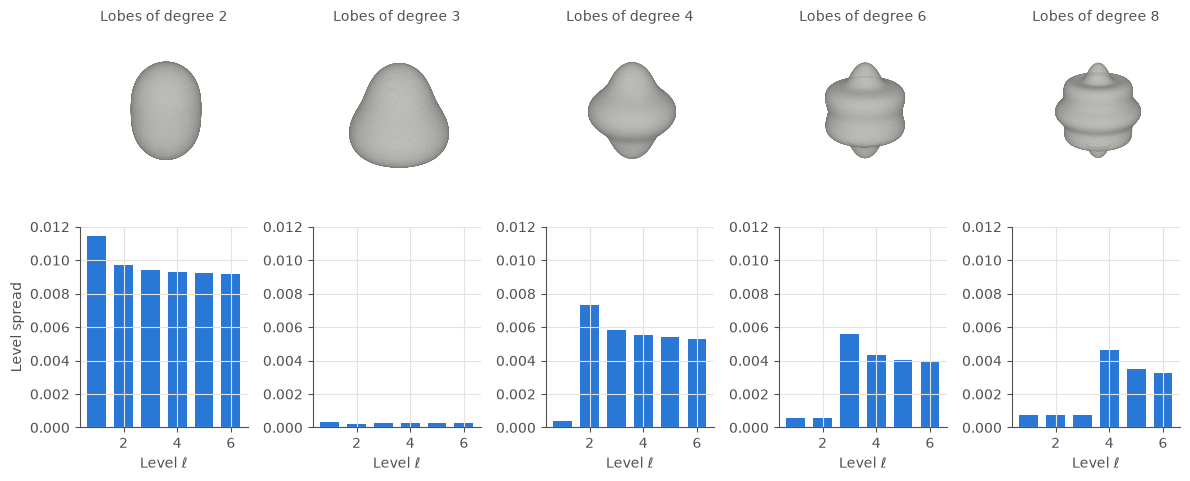

In [2]:
degrees = [2, 3, 4, 6, 8]; fig = plt.figure(figsize=(12, 5))
for i, d in enumerate(degrees):
    m = lobed_sphere(d, 0.25, subdivisions=5); ax = fig.add_subplot(2, 5, i + 1, projection="3d"); draw_mesh(ax, m); ax.set_title(f"Lobes of degree {d}", fontsize=10, color=INK)
    s = sphere_level_spread(lb_spectrum(lobed_sphere(d, 0.02), 49, False)); ax = fig.add_subplot(2, 5, i + 6)
    ax.bar(np.arange(1, 7), s, color=BLUE, width=0.7); ax.set(xlabel="Level ℓ", ylim=(0, 0.012)); ax.set_ylabel("Level spread" if i == 0 else "")
plt.tight_layout(); plt.savefig("../docs/assets/lb-3d-lobes.png", dpi=130); plt.show()

The 3D shapes exaggerate the lobes (ε = 0.25) so they are visible; the bars use ε = 0.02, where the theory applies. Each even degree $d$ first shows at level $d/2$. Degree 3 stays near zero.

## 4. Results

### Did size matching work?

In [3]:
d = np.load("../results/lb-roundness/spectra.npz")
lam, area, volume, euler, n, extents = d["lam"], d["area"], d["volume"], d["euler"], d["vertices"], np.sort(d["extents"], -1)
LABELS = ["σ = 0.04 V^(1/3)", "σ = 0.08 V^(1/3)"]; na = lam * area[..., None]; ratio = na[:, :, 1] / (8 * np.pi)
sphericity, elongation = 36 * np.pi * volume ** 2 / area ** 3, extents[:, :, 2] / extents[:, :, 0]
idx = (1, 5, 20, 50, 100, 150)
leak = pd.DataFrame({LABELS[s]: {f"λ·Area, k={k}": spearmanr(na[:, s, k], volume[:, s])[0] for k in idx} | {"Vertices": spearmanr(n[:, s], volume[:, s])[0]} for s in range(2)}).T
display(leak.round(3).style.format(precision=3).set_caption("Spearman with volume. On fixed grids, these reached 0.96"))
pd.DataFrame({LABELS[s]: {"Share genus 0": (euler[:, s] == 2).mean(), "Median vertices": np.median(n[:, s])} for s in range(2)}).round(3)

,"λ·Area, k=1","λ·Area, k=5","λ·Area, k=20","λ·Area, k=50","λ·Area, k=100","λ·Area, k=150",Vertices
σ = 0.04 V^(1/3),0.057,0.099,-0.050,0.058,-0.078,-0.152,-0.074
σ = 0.08 V^(1/3),0.060,0.104,0.008,0.074,-0.011,-0.209,-0.259


,σ = 0.04 V^(1/3),σ = 0.08 V^(1/3)
Share genus 0,0.93,0.99
Median vertices,5597.00,4719.00


### Hersch's bound and what the ratio measures

In [4]:
rows = {}
for s in range(2):
    g = euler[:, s] == 2; r = ratio[:, s]; ks = np.arange(1, 100)
    rows[LABELS[s]] = {"Genus-0 lesions": g.sum(), "Violations of Hersch": (r[g] > 1).sum(), "Largest ratio": r[g].max(), "Median ratio": np.median(r[g]), "5th percentile": np.percentile(r[g], 5),
                       "Largest λk·Area / 8πk, k<100": np.nanmax(na[g][:, s, 1:100] / (8 * np.pi * ks)), "Spearman, ratio and sphericity": spearmanr(r, sphericity[:, s])[0], "Spearman, ratio and elongation": spearmanr(r, elongation[:, s])[0], "Spearman, ratio and volume": spearmanr(r, volume[:, s])[0],
                       "Median spread, level 1": np.median([sphere_level_spread(l[np.isfinite(l)])[0] for l in lam[:, s]])}
pd.DataFrame(rows).round(3)

,σ = 0.04 V^(1/3),σ = 0.08 V^(1/3)
Genus-0 lesions,186.000,198.000
Violations of Hersch,0.000,0.000
Largest ratio,0.883,0.894
Median ratio,0.610,0.634
5th percentile,0.373,0.374
"Largest λk·Area / 8πk, k<100",0.883,0.894
"Spearman, ratio and sphericity",0.493,0.641
"Spearman, ratio and elongation",-0.686,-0.748
"Spearman, ratio and volume",0.057,0.060
"Median spread, level 1",0.330,0.298


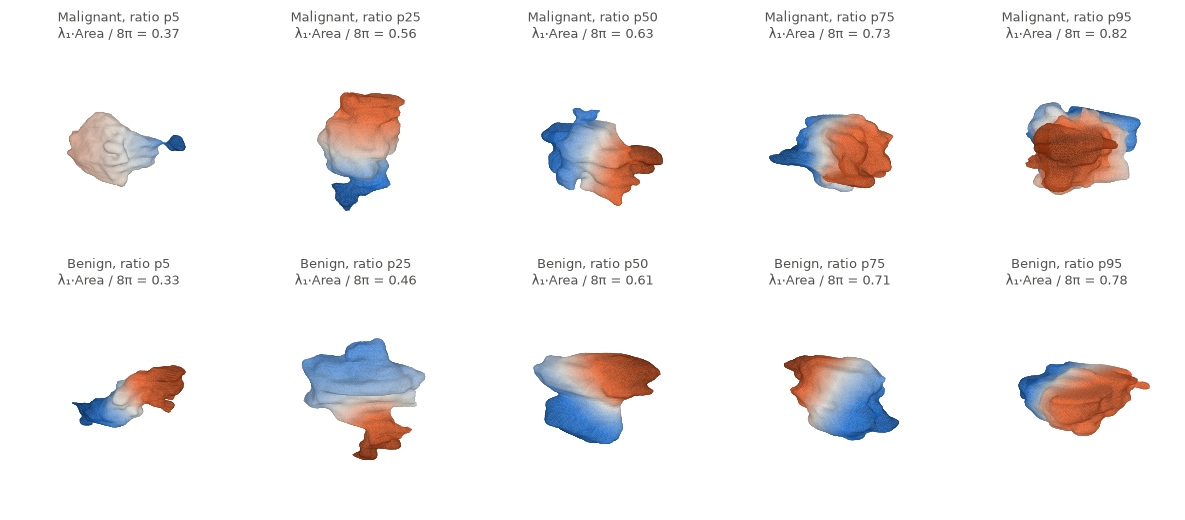

In [5]:
samples = np.load("../results/lb-roundness/sample_meshes.npz"); qs = (5, 25, 50, 75, 95); fig = plt.figure(figsize=(12, 5.2))
for row, cls in enumerate(("malignant", "benign")):
    for col, q in enumerate(qs):
        k = f"{cls}_q{q}"; m = trimesh.Trimesh(samples[k + "_vertices"].astype(float), samples[k + "_faces"], process=False)
        _, phi = compute_eigendecomposition(*compute_laplace_beltrami_operator(m), k=4); v = phi[:, 1]; limit = np.percentile(np.abs(v), 98)
        ax = fig.add_subplot(2, 5, row * 5 + col + 1, projection="3d"); draw_mesh(ax, m, v, DIVERGING, -limit, limit)
        ax.set_title(f"{cls.capitalize()}, ratio p{q}\nλ₁·Area / 8π = {float(samples[k + '_ratio']):.2f}", fontsize=9, color=INK)
plt.tight_layout(); plt.savefig("../docs/assets/lb-3d-roundness.png", dpi=130); plt.show()

Each panel is a real Train lesion, rescaled to fit, coloured by the first eigenfunction $\phi_1$, whose sign has no meaning. Reading left to right, the ratio rises towards 1. Each shape's own long axis sets $\phi_1$: low ratios belong to long or branched shapes split end to end.

### Signal beyond volume

Train+Validation only. Five-fold CV repeated 20 times. "After volume" regresses log volume out of each feature first.

In [6]:
tv = ~d["test"]; y = d["y"][tv]
def cv(X, repeats=20):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    return np.mean([roc_auc_score(y, cross_val_predict(m, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=s), method="decision_function")) for s in range(repeats)])
def cv_forest(X):
    m = RandomForestClassifier(500, min_samples_leaf=3, random_state=0, n_jobs=-1)
    return np.mean([roc_auc_score(y, cross_val_predict(m, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=s), method="predict_proba")[:, 1]) for s in range(5)])
def after_volume(X, v): return X - LinearRegression().fit(v, X).predict(v)
tables = {}
for s in range(2):
    v = np.log(volume[tv, s])[:, None]; spread = np.log([sphere_level_spread(l[np.isfinite(l)]) for l in lam[tv, s]])
    features = {"λ₁·Area / 8π": ratio[tv, s, None], "Elongation": np.log(elongation[tv, s])[:, None], "Sphericity": np.log(sphericity[tv, s])[:, None], "Level spreads, ℓ=1–6": spread}
    features |= {f"λ·Area, k≤{K}": np.log(na[tv, s, 1:K + 1]) for K in (20, 50, 100)}
    tables[LABELS[s]] = {name: {"Alone": cv(X), "With volume": cv(np.c_[v, X]), "After volume": cv(after_volume(X, v))} for name, X in features.items()}
    tables[LABELS[s]]["Volume alone"] = {"Alone": cv(v), "With volume": np.nan, "After volume": np.nan}
tan = pd.read_csv("../results/lb-spectrum-content/tan_control.csv")[["SPmean", "SP90", "SP75"]].values[tv]; v = np.log(volume[tv, 0])[:, None]
for name, t in tables.items(): t["Control: Tan spiculation"] = {"Alone": cv(tan), "With volume": cv(np.c_[v, tan]), "After volume": cv(after_volume(tan, v))}
for name, t in tables.items(): display(pd.DataFrame(t).T.round(3).style.format(precision=3).set_caption(f"Cross-validated AUC, {name}"))
print("Random forest, lighter smoothing: volume + λ·Area k≤20 {:.3f}; λ·Area k≤20 alone {:.3f}".format(cv_forest(np.c_[v, np.log(na[tv, 0, 1:21])]), cv_forest(np.log(na[tv, 0, 1:21]))))
print("Single features, lighter smoothing, malignant as positive:")
for name, x in (("λ₁·Area / 8π", ratio[tv, 0]), ("Elongation, negated", -elongation[tv, 0]), ("Volume", volume[tv, 0])):
    print("  {}: AUC {:.3f} [{:.3f}, {:.3f}]".format(name, roc_auc_score(y, x), *auc_ci(y, x)))

,Alone,With volume,After volume
λ₁·Area / 8π,0.587,0.717,0.573
Elongation,0.643,0.746,0.632
Sphericity,0.419,0.693,0.457
"Level spreads, ℓ=1–6",0.523,0.686,0.506
"λ·Area, k≤20",0.540,0.629,0.484
"λ·Area, k≤50",0.495,0.566,0.423
"λ·Area, k≤100",0.445,0.531,0.393
Volume alone,0.708,nan,nan
Control: Tan spiculation,0.788,0.802,0.693


,Alone,With volume,After volume
λ₁·Area / 8π,0.595,0.719,0.575
Elongation,0.631,0.735,0.614
Sphericity,0.547,0.697,0.453
"Level spreads, ℓ=1–6",0.570,0.694,0.535
"λ·Area, k≤20",0.590,0.687,0.547
"λ·Area, k≤50",0.547,0.619,0.469
"λ·Area, k≤100",0.570,0.624,0.455
Volume alone,0.708,nan,nan
Control: Tan spiculation,0.788,0.802,0.693


Random forest, lighter smoothing: volume + λ·Area k≤20 0.659; λ·Area k≤20 alone 0.594
Single features, lighter smoothing, malignant as positive:


  λ₁·Area / 8π: AUC 0.605 [0.507, 0.703]


  Elongation, negated: AUC 0.656 [0.561, 0.745]


  Volume: AUC 0.720 [0.631, 0.804]


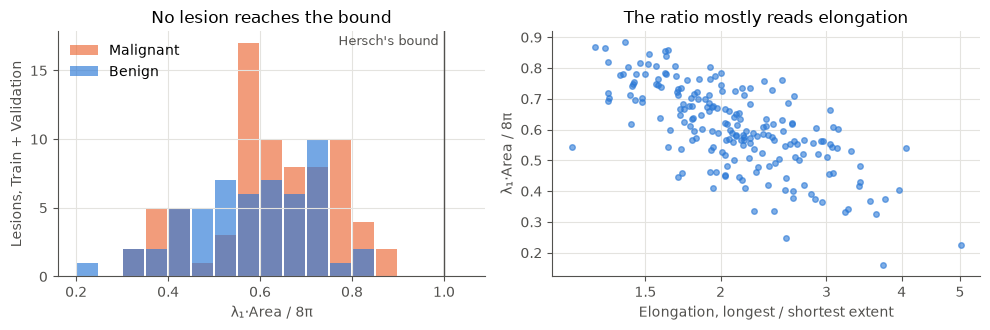

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4)); r = ratio[tv, 0]
bins = np.linspace(0.2, 1.05, 18)
ax[0].hist(r[y == 1], bins, color=ORANGE, alpha=.65, rwidth=.92, label="Malignant"); ax[0].hist(r[y == 0], bins, color=BLUE, alpha=.65, rwidth=.92, label="Benign")
ax[0].axvline(1, color=INK, lw=1); ax[0].annotate("Hersch's bound", (1, ax[0].get_ylim()[1]), xytext=(-4, -2), textcoords="offset points", ha="right", va="top", color=INK, fontsize=9)
ax[0].set(xlabel="λ₁·Area / 8π", ylabel="Lesions, Train + Validation", title="No lesion reaches the bound"); ax[0].legend(frameon=False, loc="upper left")
ax[1].plot(elongation[:, 0], ratio[:, 0], "o", ms=4, color=BLUE, alpha=.6); ax[1].set(xscale="log", xlabel="Elongation, longest / shortest extent", ylabel="λ₁·Area / 8π", title="The ratio mostly reads elongation")
ax[1].set_xticks([1.5, 2, 3, 4, 5], ["1.5", "2", "3", "4", "5"]); ax[1].minorticks_off(); ax[0].yaxis.get_major_locator().set_params(integer=True)
plt.tight_layout(); plt.savefig("../docs/assets/lb-hersch.png", dpi=150); plt.show()

## 5. Conclusions

- **Size matching fixes the leak.** $\lambda_k\cdot$Area no longer tracks volume, so future comparisons should use these surfaces.
- **Hersch's bound holds on every genus-0 lesion**, and no lesion is near it. The ratio's main content is elongation, which it reads less directly than a simple extent ratio, and it is only moderately related to sphericity.
- **The selection rule is exact on near-round shapes but does not reach real lesions.** Their level-1 spread is around 0.3, far beyond the 0.01 scale where the first-order theory was verified, so level spreads should not be read as lobe counts on them.
- **Beyond volume, little is left.** After removing volume, $\lambda_1$ keeps about 0.57 and higher modes fall to chance or below. With volume, $\lambda_1$ gives 0.72 against 0.71 for volume alone. A random forest on 20 modes does no better (0.66 with volume). A plain extent ratio does better than any spectral value: 0.63 after volume and 0.75 with it. Malignant lesions here are less elongated than benign ones, but many comparisons were made on 130 lesions, so this is a hypothesis to test, not a finding.

## 6. Protocol

All 200 lesions for geometry; labels on the 130 Train+Validation lesions only. Malignant is positive. A rerun matched the stored eigenvalues to about 5e-13. CPU only, no Kaggle kernel. Stored results: `results/lb-roundness/`. The challenge benchmark does not apply: nothing here produces predictions.

## 7. Open issues

- **Stability.** How much do these values move under segmentation error? That is the next roadmap step, and it may explain the weak signal.
- **Local features.** All tests here are on global numbers. HKS and WKS maps could keep local protrusions that global summaries average away. Spiculation's strength suggests local detail matters, but it also uses image intensities.
- **Elongation in the ESWA context.** Whether adding elongation to an image model helps has not been tested.